
--- First 5 Rows of the Dataset ---


,id,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,0,Male,24.443011,1.699998,81.669950,yes,yes,2.000000,2.983297,Sometimes,no,2.763573,no,0.000000,0.976473,Sometimes,Public_Transportation,Overweight_Level_II
1,1,Female,18.000000,1.560000,57.000000,yes,yes,2.000000,3.000000,Frequently,no,2.000000,no,1.000000,1.000000,no,Automobile,Normal_Weight
2,2,Female,18.000000,1.711460,50.165754,yes,yes,1.880534,1.411685,Sometimes,no,1.910378,no,0.866045,1.673584,no,Public_Transportation,Insufficient_Weight
3,3,Female,20.952737,1.710730,131.274851,yes,yes,3.000000,3.000000,Sometimes,no,1.674061,no,1.467863,0.780199,Sometimes,Public_Transportation,Obesity_Type_III
4,4,Male,31.641081,1.914186,93.798055,yes,yes,2.679664,1.971472,Sometimes,no,1.979848,no,1.967973,0.931721,Sometimes,Public_Transportation,Overweight_Level_II



--- Generating Color-Coded Correlation Matrix ---


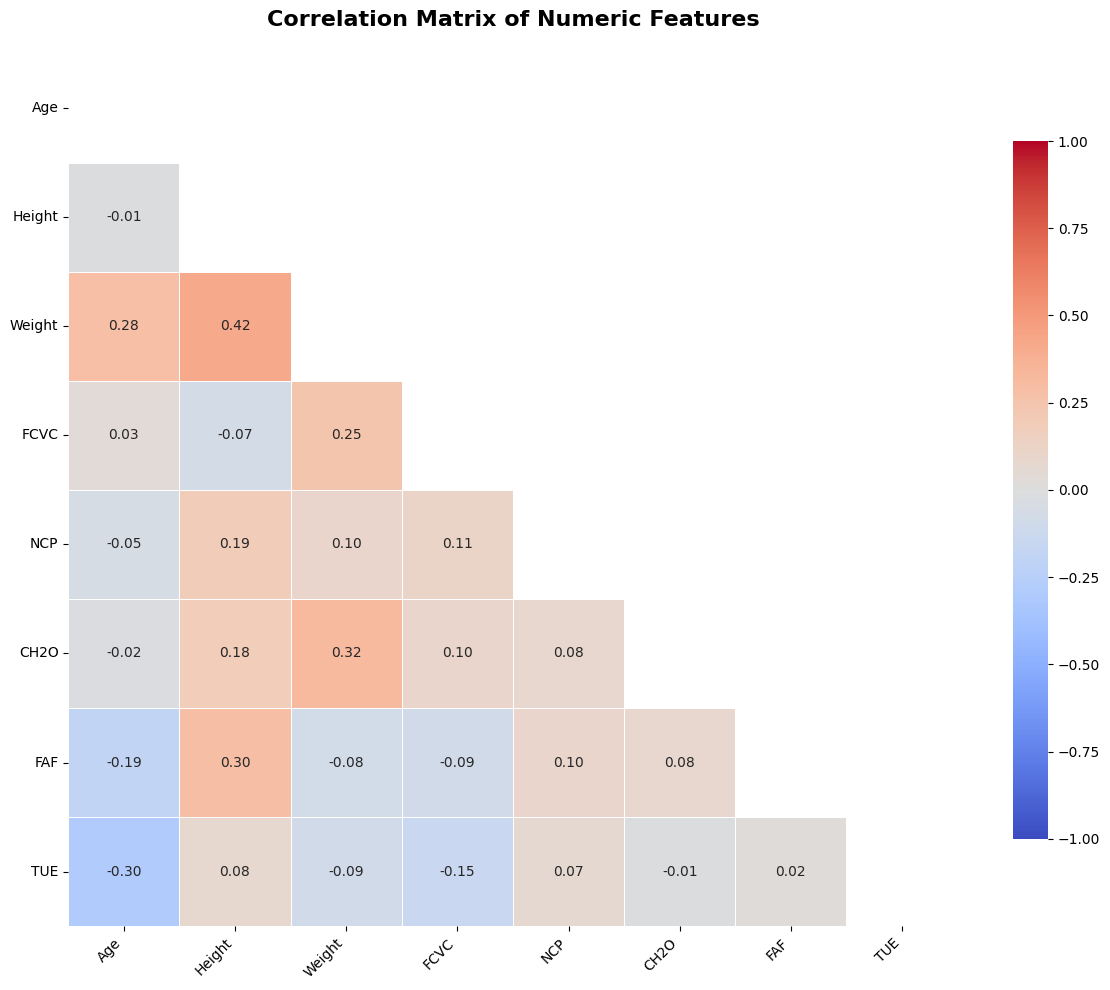


--- Generating Pairwise Scatterplots (Optimized Subsample) ---


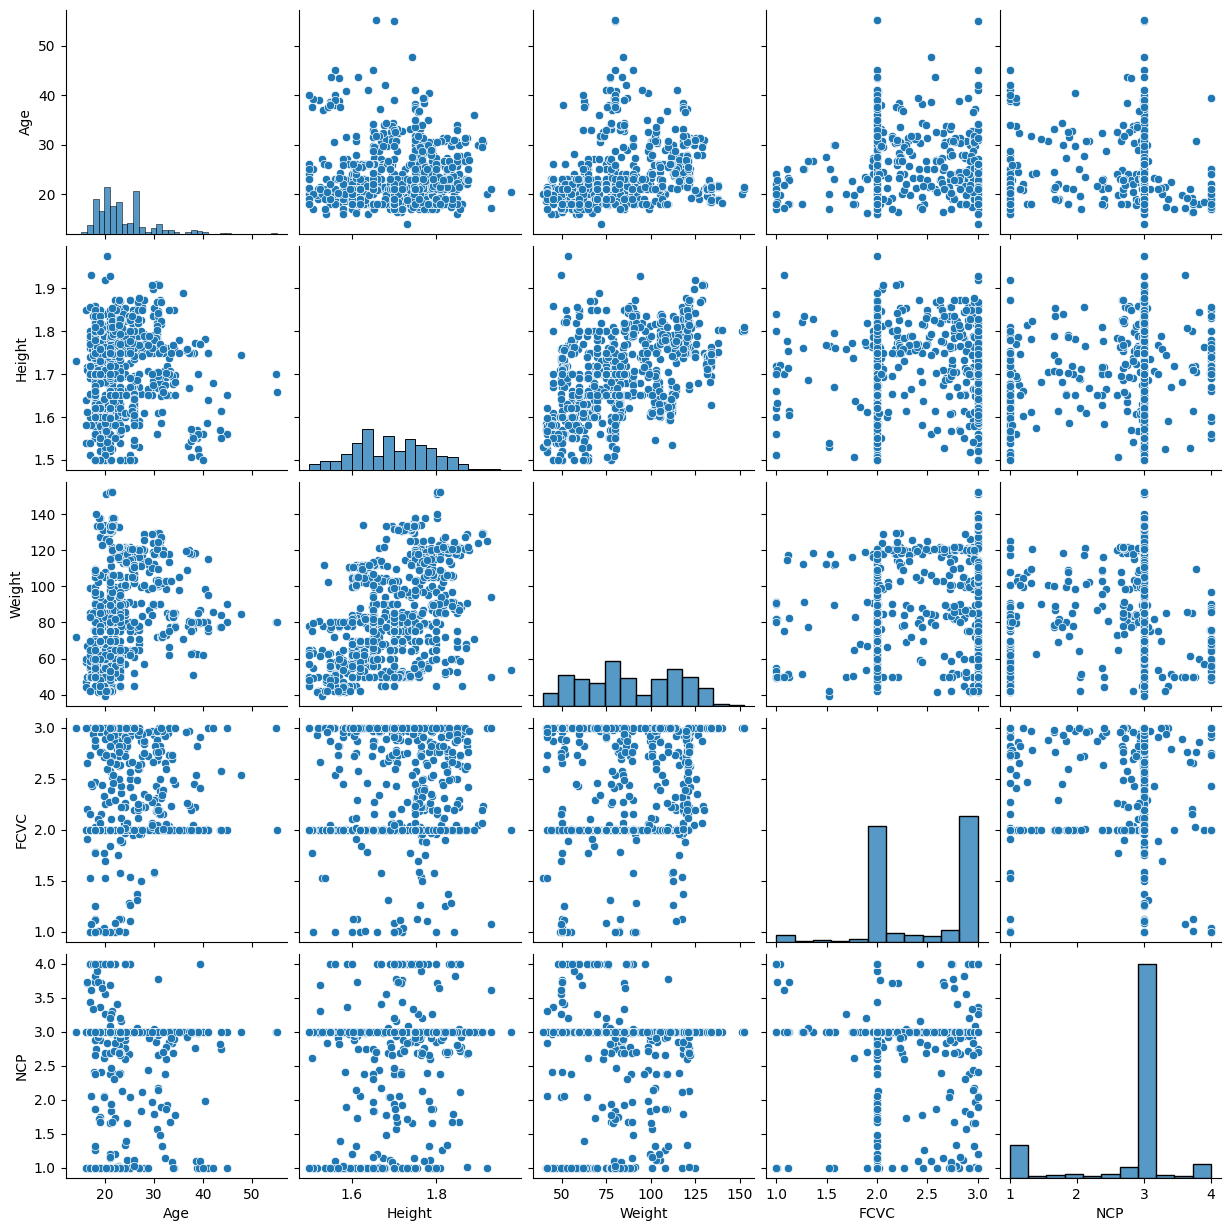


--- Preparing Data for Boosted Model (LightGBM) ---
Training LightGBM Boosted Model...

Boosted Model (LightGBM) Validation Accuracy: 0.9092

--- Classification Report ---
                     precision    recall  f1-score   support

Insufficient_Weight       0.94      0.94      0.94       505
      Normal_Weight       0.88      0.89      0.89       617
     Obesity_Type_I       0.88      0.89      0.89       582
    Obesity_Type_II       0.97      0.97      0.97       650
   Obesity_Type_III       1.00      1.00      1.00       809
 Overweight_Level_I       0.82      0.78      0.80       485
Overweight_Level_II       0.81      0.83      0.82       504

           accuracy                           0.91      4152
          macro avg       0.90      0.90      0.90      4152
       weighted avg       0.91      0.91      0.91      4152



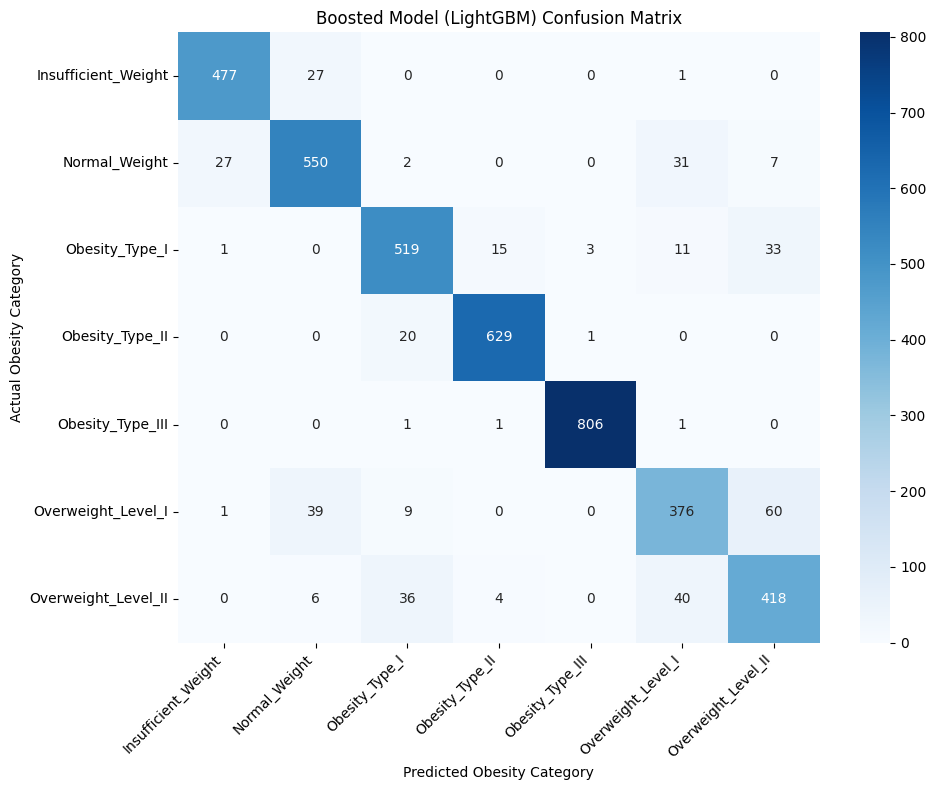

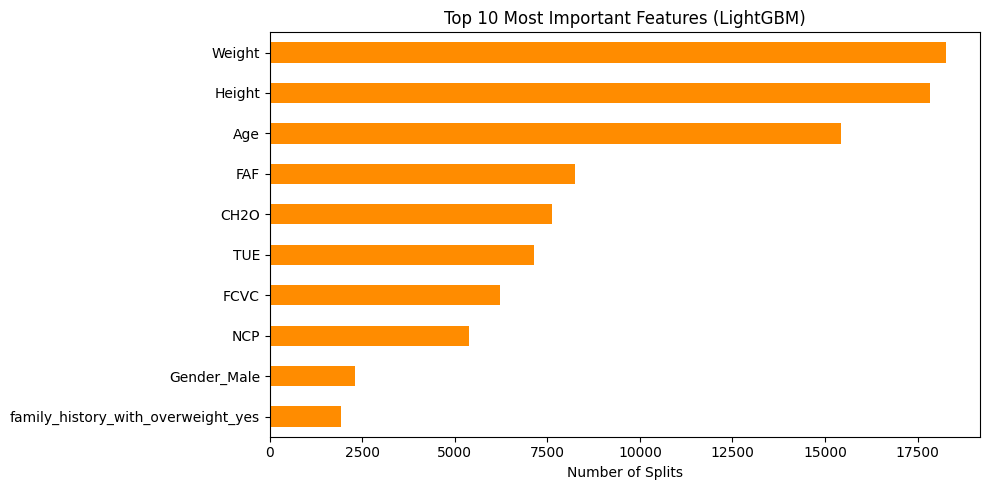

Generating final test predictions...

--- Submission Preview ---
      id          NObeyesdad
0  20758     Obesity_Type_II
1  20759  Overweight_Level_I
2  20760    Obesity_Type_III
3  20761      Obesity_Type_I
4  20762    Obesity_Type_III

Successfully generated submission.csv with 13840 rows!

👇 CLICK THE LINK BELOW TO DOWNLOAD YOUR SUBMISSION FILE 👇


/kaggle/working/submission.csv

In [6]:
# Multi-Class Prediction of Obesity Risk
# (4 of 4) boosted model 


import os
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# ==========================================
# A. Get the training dataset. 
# ==========================================
# 1. Target the dataset path 
file_path = '/kaggle/input/playground-series-s4e2/train.csv'

# Fallback block: dynamically scans if paths change slightly
if not os.path.exists(file_path):
    for dirname, _, filenames in os.walk('/kaggle/input'):
        for filename in filenames:
            if filename.endswith('.csv') and 'train' in filename:
                file_path = os.path.join(dirname, filename)
                break

# Load the full dataset
df = pd.read_csv(file_path)


# ==========================================
# B. Show correlations and the first 5 rows. 
# ==========================================

# 2. Display the first 5 rows
print("\n--- First 5 Rows of the Dataset ---")
if 'display' in globals():
    display(df.head())
else:
    print(df.head())


# 3. Plot a Color-Coded Correlation Matrix Heatmap (Runs instantly)
print("\n--- Generating Color-Coded Correlation Matrix ---")

# Isolate numeric fields and drop structural identifiers
numeric_df = df.select_dtypes(include=[np.number])
if 'id' in numeric_df.columns:
    numeric_df = numeric_df.drop(columns=['id'])

corr_matrix = numeric_df.corr()

plt.figure(figsize=(12, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool)) # Trim redundant half

sns.heatmap(
    corr_matrix, 
    mask=mask, 
    cmap='coolwarm', 
    vmax=1.0, 
    vmin=-1.0, 
    center=0,
    annot=True,          
    fmt=".2f",           
    linewidths=0.5,      
    cbar_kws={"shrink": 0.8} 
)

plt.title('Correlation Matrix of Numeric Features', fontsize=16, fontweight='bold', pad=20)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


# 4. Plot Optimized Pairwise Scatterplots (Downsampled for speed)
print("\n--- Generating Pairwise Scatterplots (Optimized Subsample) ---")
numeric_cols = numeric_df.columns.tolist()
sample_df = df.sample(n=min(1000, len(df)), random_state=42)
sns.pairplot(sample_df[numeric_cols[:5]])  
plt.show()


# ==========================================
# C. Build and Evaluate a Boosted Model (LightGBM)
# ==========================================
from lightgbm import LGBMClassifier

print("\n--- Preparing Data for Boosted Model (LightGBM) ---")

# 1. Separate features (X) and target (y), dropping 'id' if present
X = df.drop(columns=['NObeyesdad', 'id'], errors='ignore')
y = df['NObeyesdad']

# 2. Encode the target classes (7 obesity categories -> integers 0 to 6)
target_encoder = LabelEncoder()
y_encoded = target_encoder.fit_transform(y)

# 3. One-hot encode categorical text features (e.g., Gender, MTRANS, FAVC)
X_encoded = pd.get_dummies(X, drop_first=True)

# 4. Split into training (80%) and validation (20%) sets
X_train, X_val, y_train, y_val = train_test_split(
    X_encoded, 
    y_encoded, 
    test_size=0.2, 
    random_state=42, 
    stratify=y_encoded
)

# 5. Initialize and train the Boosted Model
boosted_model = LGBMClassifier(
    n_estimators=500,          # Builds up to 500 sequential trees
    learning_rate=0.05,        # Small step size so each tree gently corrects prior errors
    num_leaves=31,             # Controls tree complexity
    subsample_for_bin=50000,
    colsample_bytree=0.8,      # Uses 80% of features per tree to prevent overfitting
    subsample=0.8,             # Uses 80% of rows per tree
    random_state=42,
    n_jobs=-1,
    verbose=-1                 # Keeps console output clean
)

print("Training LightGBM Boosted Model...")
boosted_model.fit(X_train, y_train)

# 6. Make predictions and evaluate
y_pred = boosted_model.predict(X_val)

accuracy = accuracy_score(y_val, y_pred)
print(f"\nBoosted Model (LightGBM) Validation Accuracy: {accuracy:.4f}")

print("\n--- Classification Report ---")
print(classification_report(
    y_val, 
    y_pred, 
    target_names=target_encoder.classes_
))

# 7. Plot the Confusion Matrix
plt.figure(figsize=(10, 8))
cm = confusion_matrix(y_val, y_pred)
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues',
    xticklabels=target_encoder.classes_,
    yticklabels=target_encoder.classes_
)
plt.title('Boosted Model (LightGBM) Confusion Matrix')
plt.ylabel('Actual Obesity Category')
plt.xlabel('Predicted Obesity Category')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# 8. Display Top 10 Most Important Features
feature_importances = pd.Series(boosted_model.feature_importances_, index=X_train.columns)
plt.figure(figsize=(10, 5))
feature_importances.nlargest(10).sort_values().plot(kind='barh', color='darkorange')
plt.title('Top 10 Most Important Features (LightGBM)')
plt.xlabel('Number of Splits')
plt.tight_layout()
plt.show()



# ==========================================
# D. Export file on testing portion
# ==========================================
import os
import pandas as pd
from IPython.display import FileLink, display

# --- 1. Locate and Load the Test Dataset ---
test_file_path = '/kaggle/input/playground-series-s4e2/test.csv'

if not os.path.exists(test_file_path):
    for dirname, _, filenames in os.walk('/kaggle/input'):
        for filename in filenames:
            if filename.endswith('.csv') and 'test' in filename:
                test_file_path = os.path.join(dirname, filename)
                break

test_df = pd.read_csv(test_file_path)

# --- 2. Extract IDs and Preprocess Categorical Features ---
test_ids = test_df['id']
X_test = test_df.drop(columns=['id'], errors='ignore')

# One-hot encode the test set categorical features
X_test_encoded = pd.get_dummies(X_test, drop_first=True)

# Align columns with training features layout (handles any missing categories in test)
X_test_encoded = X_test_encoded.reindex(columns=X_train.columns, fill_value=0)

# --- 3. Generate Predictions & Decode Labels ---
# Note: Scaling is removed because dt_model was trained on unscaled X_train
print("Generating final test predictions...")
test_predictions_encoded = boosted_model.predict(X_test_encoded)

# Convert integer predictions (0-6) back to original string labels
test_predictions = target_encoder.inverse_transform(test_predictions_encoded)

# --- 4. Create and Export Submission DataFrame ---
submission_df = pd.DataFrame({
    'id': test_ids,
    'NObeyesdad': test_predictions
})

# Preview first 5 predictions to verify format
print("\n--- Submission Preview ---")
print(submission_df.head())

# Save to your output directory
output_path = 'submission.csv'
submission_df.to_csv(output_path, index=False)

print(f"\nSuccessfully generated {output_path} with {len(submission_df)} rows!")

# --- 5. Add Download Link ---
print("\n👇 CLICK THE LINK BELOW TO DOWNLOAD YOUR SUBMISSION FILE 👇")
display(FileLink(output_path))

